# Catalogue of Quasar Properties

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.table import Table

plt.style.use("seaborn-v0_8")


In [11]:
from astropy.io import ascii

table = ascii.read(
    "../data/catalog.dat",
    readme="../data/ReadMe"
)

print(len(table))
print(table.colnames[:10])


105783
['SDSS', 'RAdeg', 'DEdeg', 'z', 'Plate', 'Fiber', 'MJD', 'Flag', 'N', 'Uni']


In [12]:
df = table.to_pandas()

In [13]:
core_cols = [
    "z",
    "logL3000",
    "logL5100",
    "logBH",
    "e_logBH"
]

df[core_cols].head()


,z,logL3000,logL5100,logBH,e_logBH
0,1.8246,45.324,0.0,9.28,0.19
1,1.8373,45.665,0.0,9.17,0.17
2,1.1985,45.449,0.0,8.50,0.05
3,2.2342,46.199,0.0,9.66,0.31
4,1.8449,45.924,0.0,10.04,0.12


In [14]:
df[["z", "logBH"]].describe()

,z,logBH
count,105783.000000,105783.000000
mean,1.562423,8.872513
std,0.834552,1.012322
min,0.064500,0.000000
25%,0.971400,8.640000
50%,1.493700,8.990000
75%,1.954300,9.300000
max,5.460800,11.310000


In [15]:
df_clean = df[
    (df["logBH"] > 5) &        # remove invalid / placeholder values
    (df["logBH"] < 11.5) &     # remove extreme outliers
    (df["z"] > 0.1) &
    (df["z"] < 5.0)
]

In [20]:
df_fig = df[
    (df["logBH"] > 5) &
    (df["logBH"] < 11.5) &
    (df["z"] > 0.1) &
    (df["z"] < 5.0)
]


In [16]:
len(df_clean)


104725

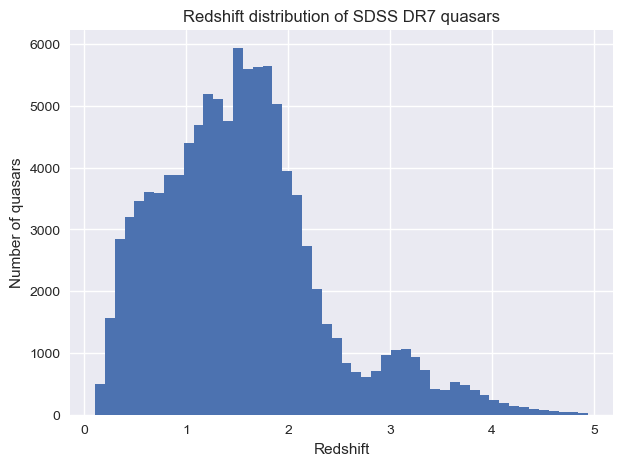

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
plt.hist(df_clean["z"], bins=50)
plt.xlabel("Redshift")
plt.ylabel("Number of quasars")
plt.title("Redshift distribution of SDSS DR7 quasars")
plt.show()

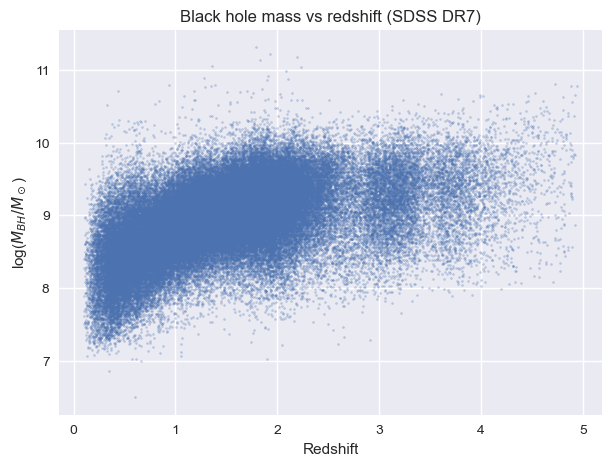

In [18]:
plt.figure(figsize=(7,5))
plt.scatter(
    df_clean["z"],
    df_clean["logBH"],
    s=2,
    alpha=0.3
)
plt.xlabel("Redshift")
plt.ylabel(r"log($M_{BH}/M_\odot$)")
plt.title("Black hole mass vs redshift (SDSS DR7)")
plt.show()


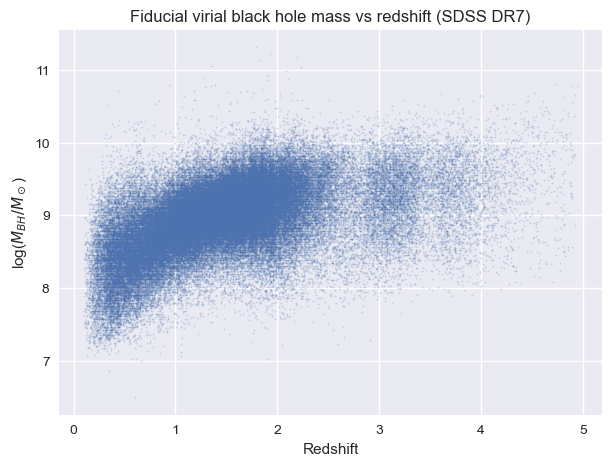

In [21]:
plt.figure(figsize=(7,5))
plt.scatter(
    df_fig["z"],
    df_fig["logBH"],
    s=1,
    alpha=0.2
)

plt.xlabel("Redshift")
plt.ylabel(r"log($M_{BH}/M_\odot$)")
plt.title("Fiducial virial black hole mass vs redshift (SDSS DR7)")
plt.show()


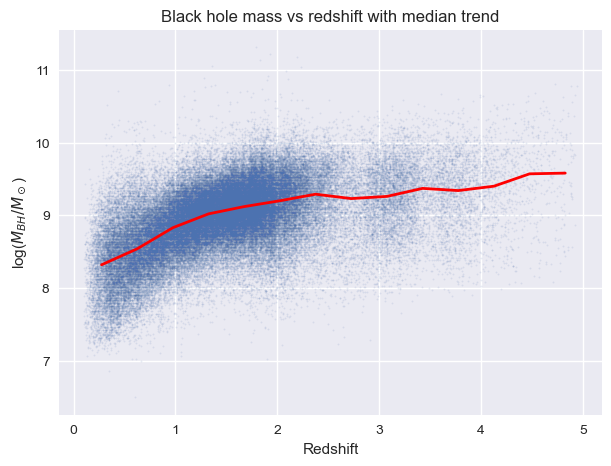

In [22]:
bins = np.linspace(0.1, 5.0, 15)
bin_centers = 0.5 * (bins[:-1] + bins[1:])

median_mass = [
    np.median(df_fig[(df_fig["z"] > bins[i]) & (df_fig["z"] <= bins[i+1])]["logBH"])
    for i in range(len(bins)-1)
]

plt.figure(figsize=(7,5))
plt.scatter(df_fig["z"], df_fig["logBH"], s=1, alpha=0.1)
plt.plot(bin_centers, median_mass, color="red", lw=2)

plt.xlabel("Redshift")
plt.ylabel(r"log($M_{BH}/M_\odot$)")
plt.title("Black hole mass vs redshift with median trend")
plt.show()


In [25]:
df_hb = df[
    (df["W(BHb)"] > 0) &
    (df["logL5100"] > 0) &
    (df["alpHb"] > -900)
]
 

In [26]:
x = df_hb["logL5100"]
y = df_hb["alpHb"]


In [27]:
import numpy as np

xbins = np.arange(x.min(), x.max(), 0.1)
ybins = np.arange(y.min(), y.max(), 0.1)

H, xedges, yedges = np.histogram2d(x, y, bins=[xbins, ybins])


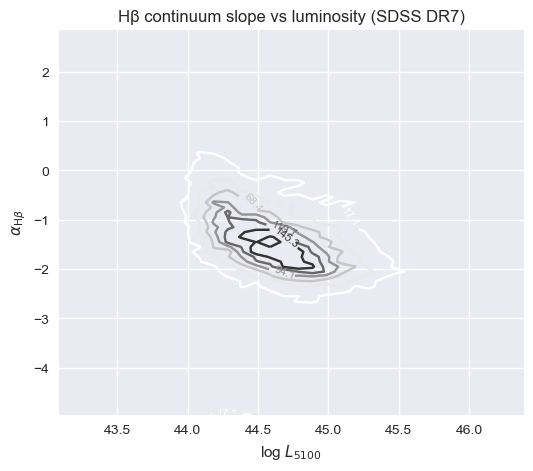

In [28]:
import matplotlib.pyplot as plt

X, Y = np.meshgrid(
    0.5 * (xedges[:-1] + xedges[1:]),
    0.5 * (yedges[:-1] + yedges[1:])
)

plt.figure(figsize=(6,5))
cs = plt.contour(
    X, Y, H.T,
    levels=np.linspace(H.max()*0.1, H.max(), 7)
)

plt.clabel(cs, inline=True, fontsize=8)
plt.xlabel(r"log $L_{5100}$")
plt.ylabel(r"$\alpha_{\mathrm{H}\beta}$")
plt.title("Hβ continuum slope vs luminosity (SDSS DR7)")
plt.show()


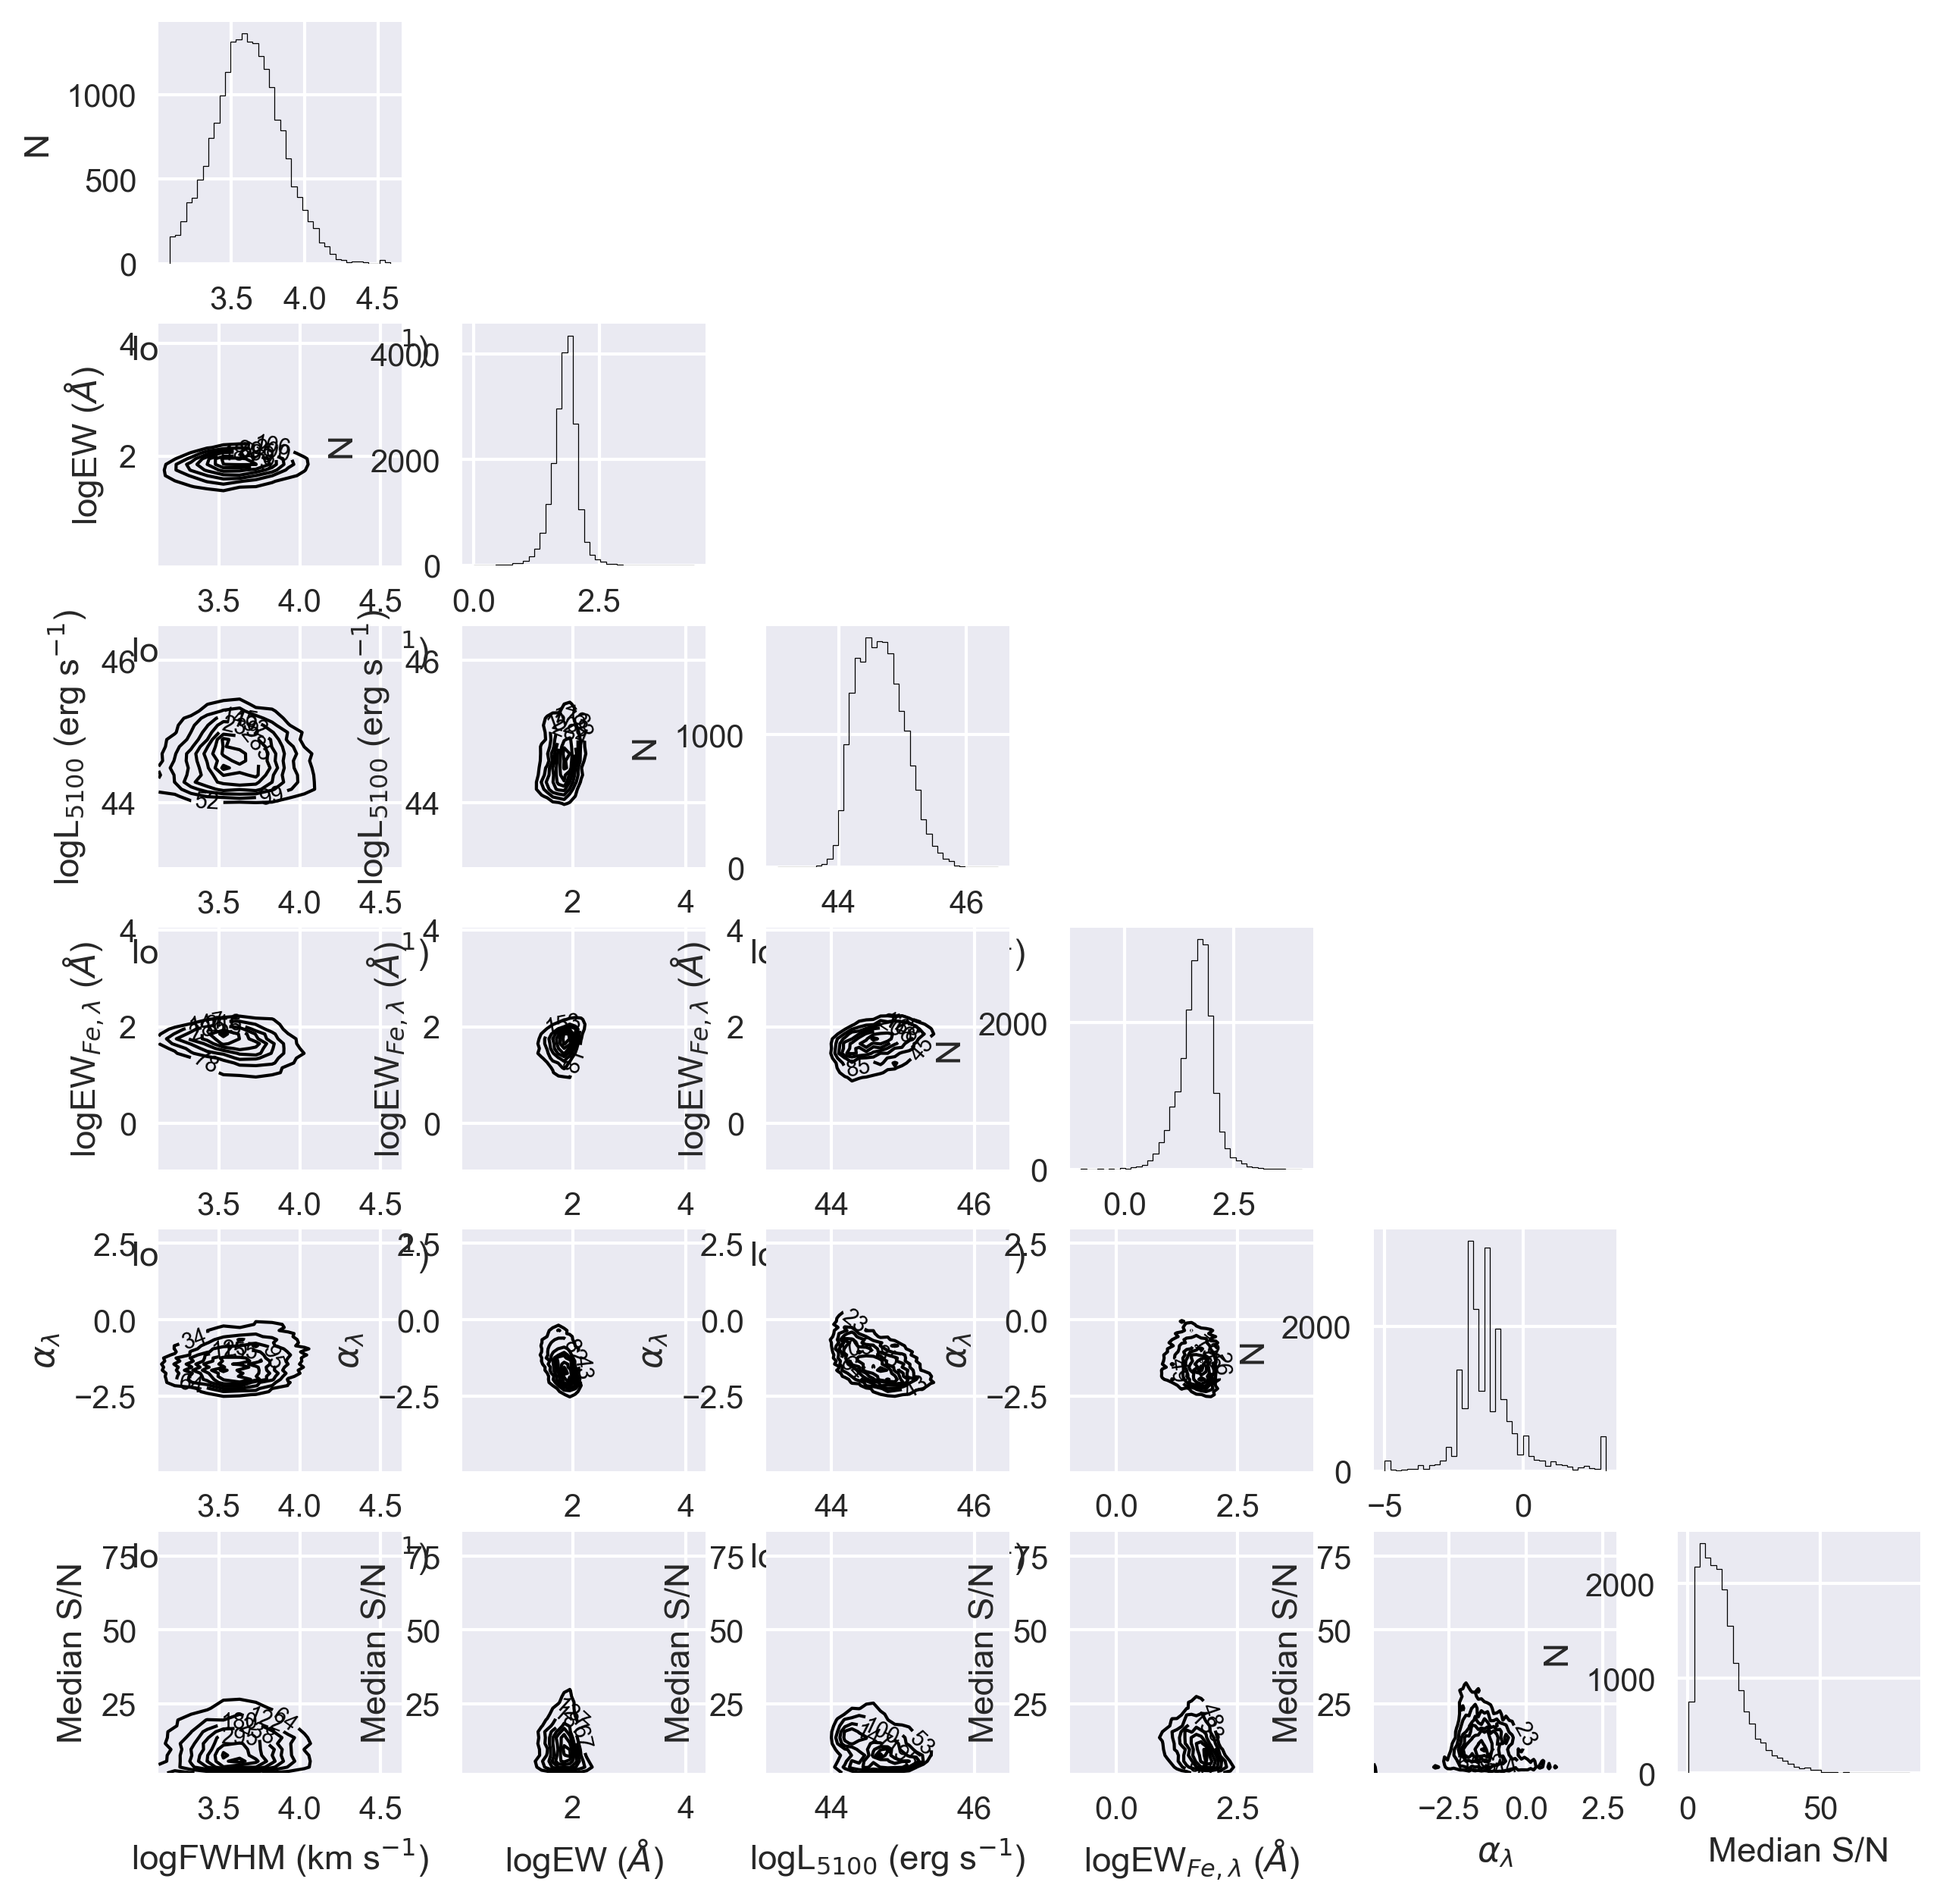

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import ascii

# 1) Read the CDS/VizieR table properly (this is the key step)
t = ascii.read("../data/catalog.dat", readme="../data/ReadMe")   # your filenames here

# 2) Pull the needed columns (names should match the ReadMe labels)
# Broad Hβ FWHM, broad Hβ EW, L5100, Fe EW (Hb region), alpha slope (Hb), median S/N (Hb)
fwhm = np.array(t["W(BHb)"], dtype=float)          # km/s
ew   = np.array(t["EWBHb"], dtype=float)           # Å (CDS unit is 0.1nm = 1 Å)
L5100 = np.array(t["logL5100"], dtype=float)       # log10 erg/s
ewfe = np.array(t["EWFeHb"], dtype=float)          # Å (same 0.1nm convention)
alpha = np.array(t["alpHb"], dtype=float)          # continuum slope
sn = np.array(t["SN(Hb)"], dtype=float)            # median S/N per pixel

# 3) Apply "measurable" filters (remove sentinels and non-positive where logs are taken)
mask = (
    (fwhm > 0) &
    (ew > 0) &
    (L5100 > 0) &
    (ewfe > 0) &
    (sn > 0) &
    (alpha > -900)   # removes -999 sentinel
)

fwhm = fwhm[mask]
ew = ew[mask]
L5100 = L5100[mask]
ewfe = ewfe[mask]
alpha = alpha[mask]
sn = sn[mask]

# 4) Transform to the plotted variables
x_logfwhm = np.log10(fwhm)
x_logew   = np.log10(ew)
x_logL5100 = L5100
x_logewfe = np.log10(ewfe)
x_alpha = alpha
x_sn = sn

vars_list = [x_logfwhm, x_logew, x_logL5100, x_logewfe, x_alpha, x_sn]
labels = [
    r"logFWHM (km s$^{-1}$)",
    r"logEW ($\AA$)",
    r"logL$_{5100}$ (erg s$^{-1}$)",
    r"logEW$_{Fe,\lambda}$ ($\AA$)",
    r"$\alpha_\lambda$",
    r"Median S/N"
]

# Bin widths per caption:
# Δ=0.1 for most axes; Δ=2 for S/N axis
binw = [0.1, 0.1, 0.1, 0.1, 0.1, 2.0]

def density_contour(ax, x, y, dx, dy, nlevels=7):
    # define bin edges
    xedges = np.arange(np.nanmin(x), np.nanmax(x) + dx, dx)
    yedges = np.arange(np.nanmin(y), np.nanmax(y) + dy, dy)

    H, xe, ye = np.histogram2d(x, y, bins=[xedges, yedges])
    # histogram2d returns H[xbin, ybin]; contour expects meshgrid
    Xc = 0.5 * (xe[:-1] + xe[1:])
    Yc = 0.5 * (ye[:-1] + ye[1:])
    XX, YY = np.meshgrid(Xc, Yc, indexing="xy")
    Z = H.T  # transpose to match XX,YY

    zmax = Z.max()
    if zmax <= 0:
        return

    # "equally spaced linearly" levels (caption)
    levels = np.linspace(zmax * 0.15, zmax * 0.95, nlevels)

    cs = ax.contour(XX, YY, Z, levels=levels, colors="k", linewidths=1.0)
    ax.clabel(cs, inline=True, fontsize=7, fmt="%d")

# 5) Build the triangular grid
n = len(vars_list)
fig, axes = plt.subplots(n, n, figsize=(10, 10), dpi=300)
plt.subplots_adjust(wspace=0.25, hspace=0.25)

for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        if i < j:
            ax.axis("off")
            continue

        if i == j:
            ax.hist(vars_list[i], bins=40, histtype="step", color="k")
            ax.set_ylabel("N")
            ax.set_xlabel(labels[i])
        else:
            x = vars_list[j]
            y = vars_list[i]
            density_contour(ax, x, y, binw[j], binw[i], nlevels=7)
            ax.set_xlabel(labels[j])
            ax.set_ylabel(labels[i])

plt.show()


In [32]:
df_edd = df[
    (df["logEdd"] > -5) &
    (df["logEdd"] < 2) &
    (df["logBH"] > 5)
]


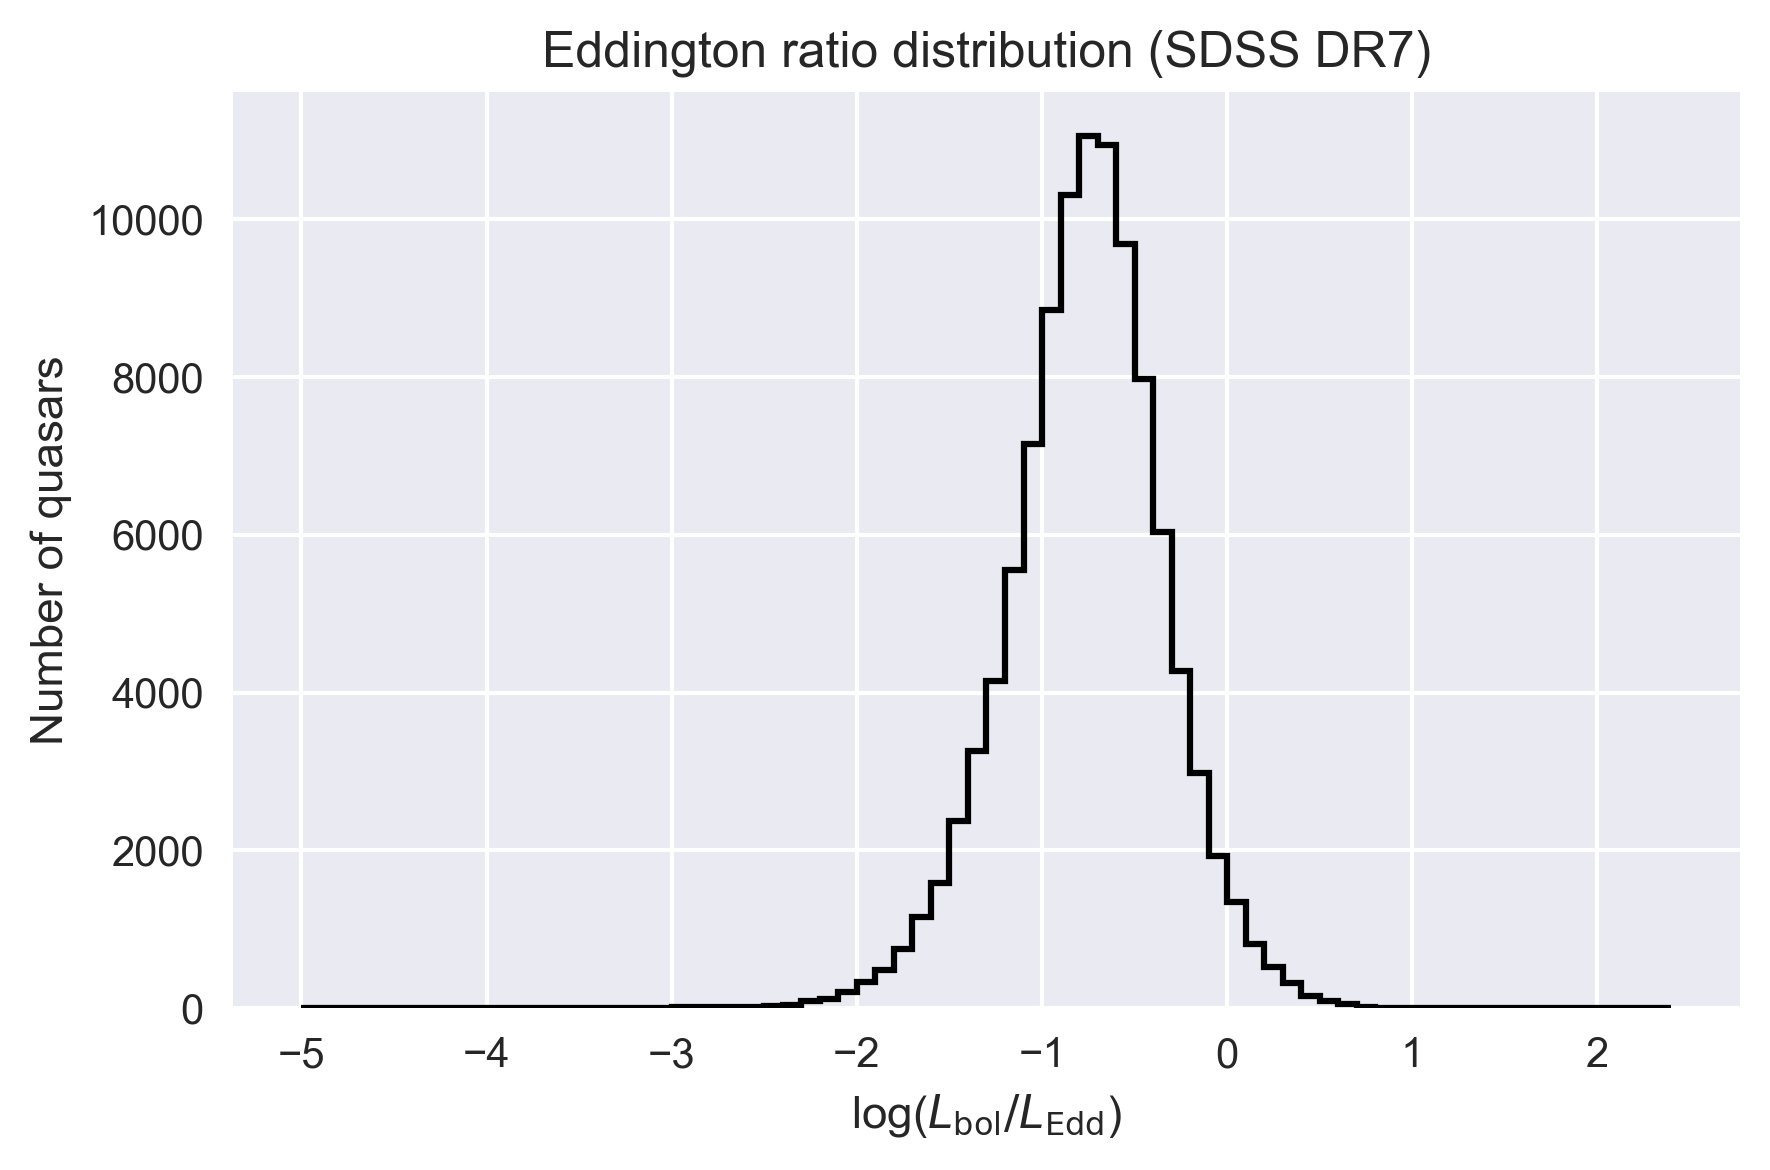

In [33]:
import numpy as np
import matplotlib.pyplot as plt

bins = np.arange(-5, 2.5, 0.1)

plt.figure(figsize=(6, 4), dpi=300)
plt.hist(
    df_edd["logEdd"],
    bins=bins,
    histtype="step",
    linewidth=1.5,
    color="black"
)

plt.xlabel(r"log($L_{\mathrm{bol}}/L_{\mathrm{Edd}}$)")
plt.ylabel("Number of quasars")
plt.title("Eddington ratio distribution (SDSS DR7)")
plt.tight_layout()
plt.show()


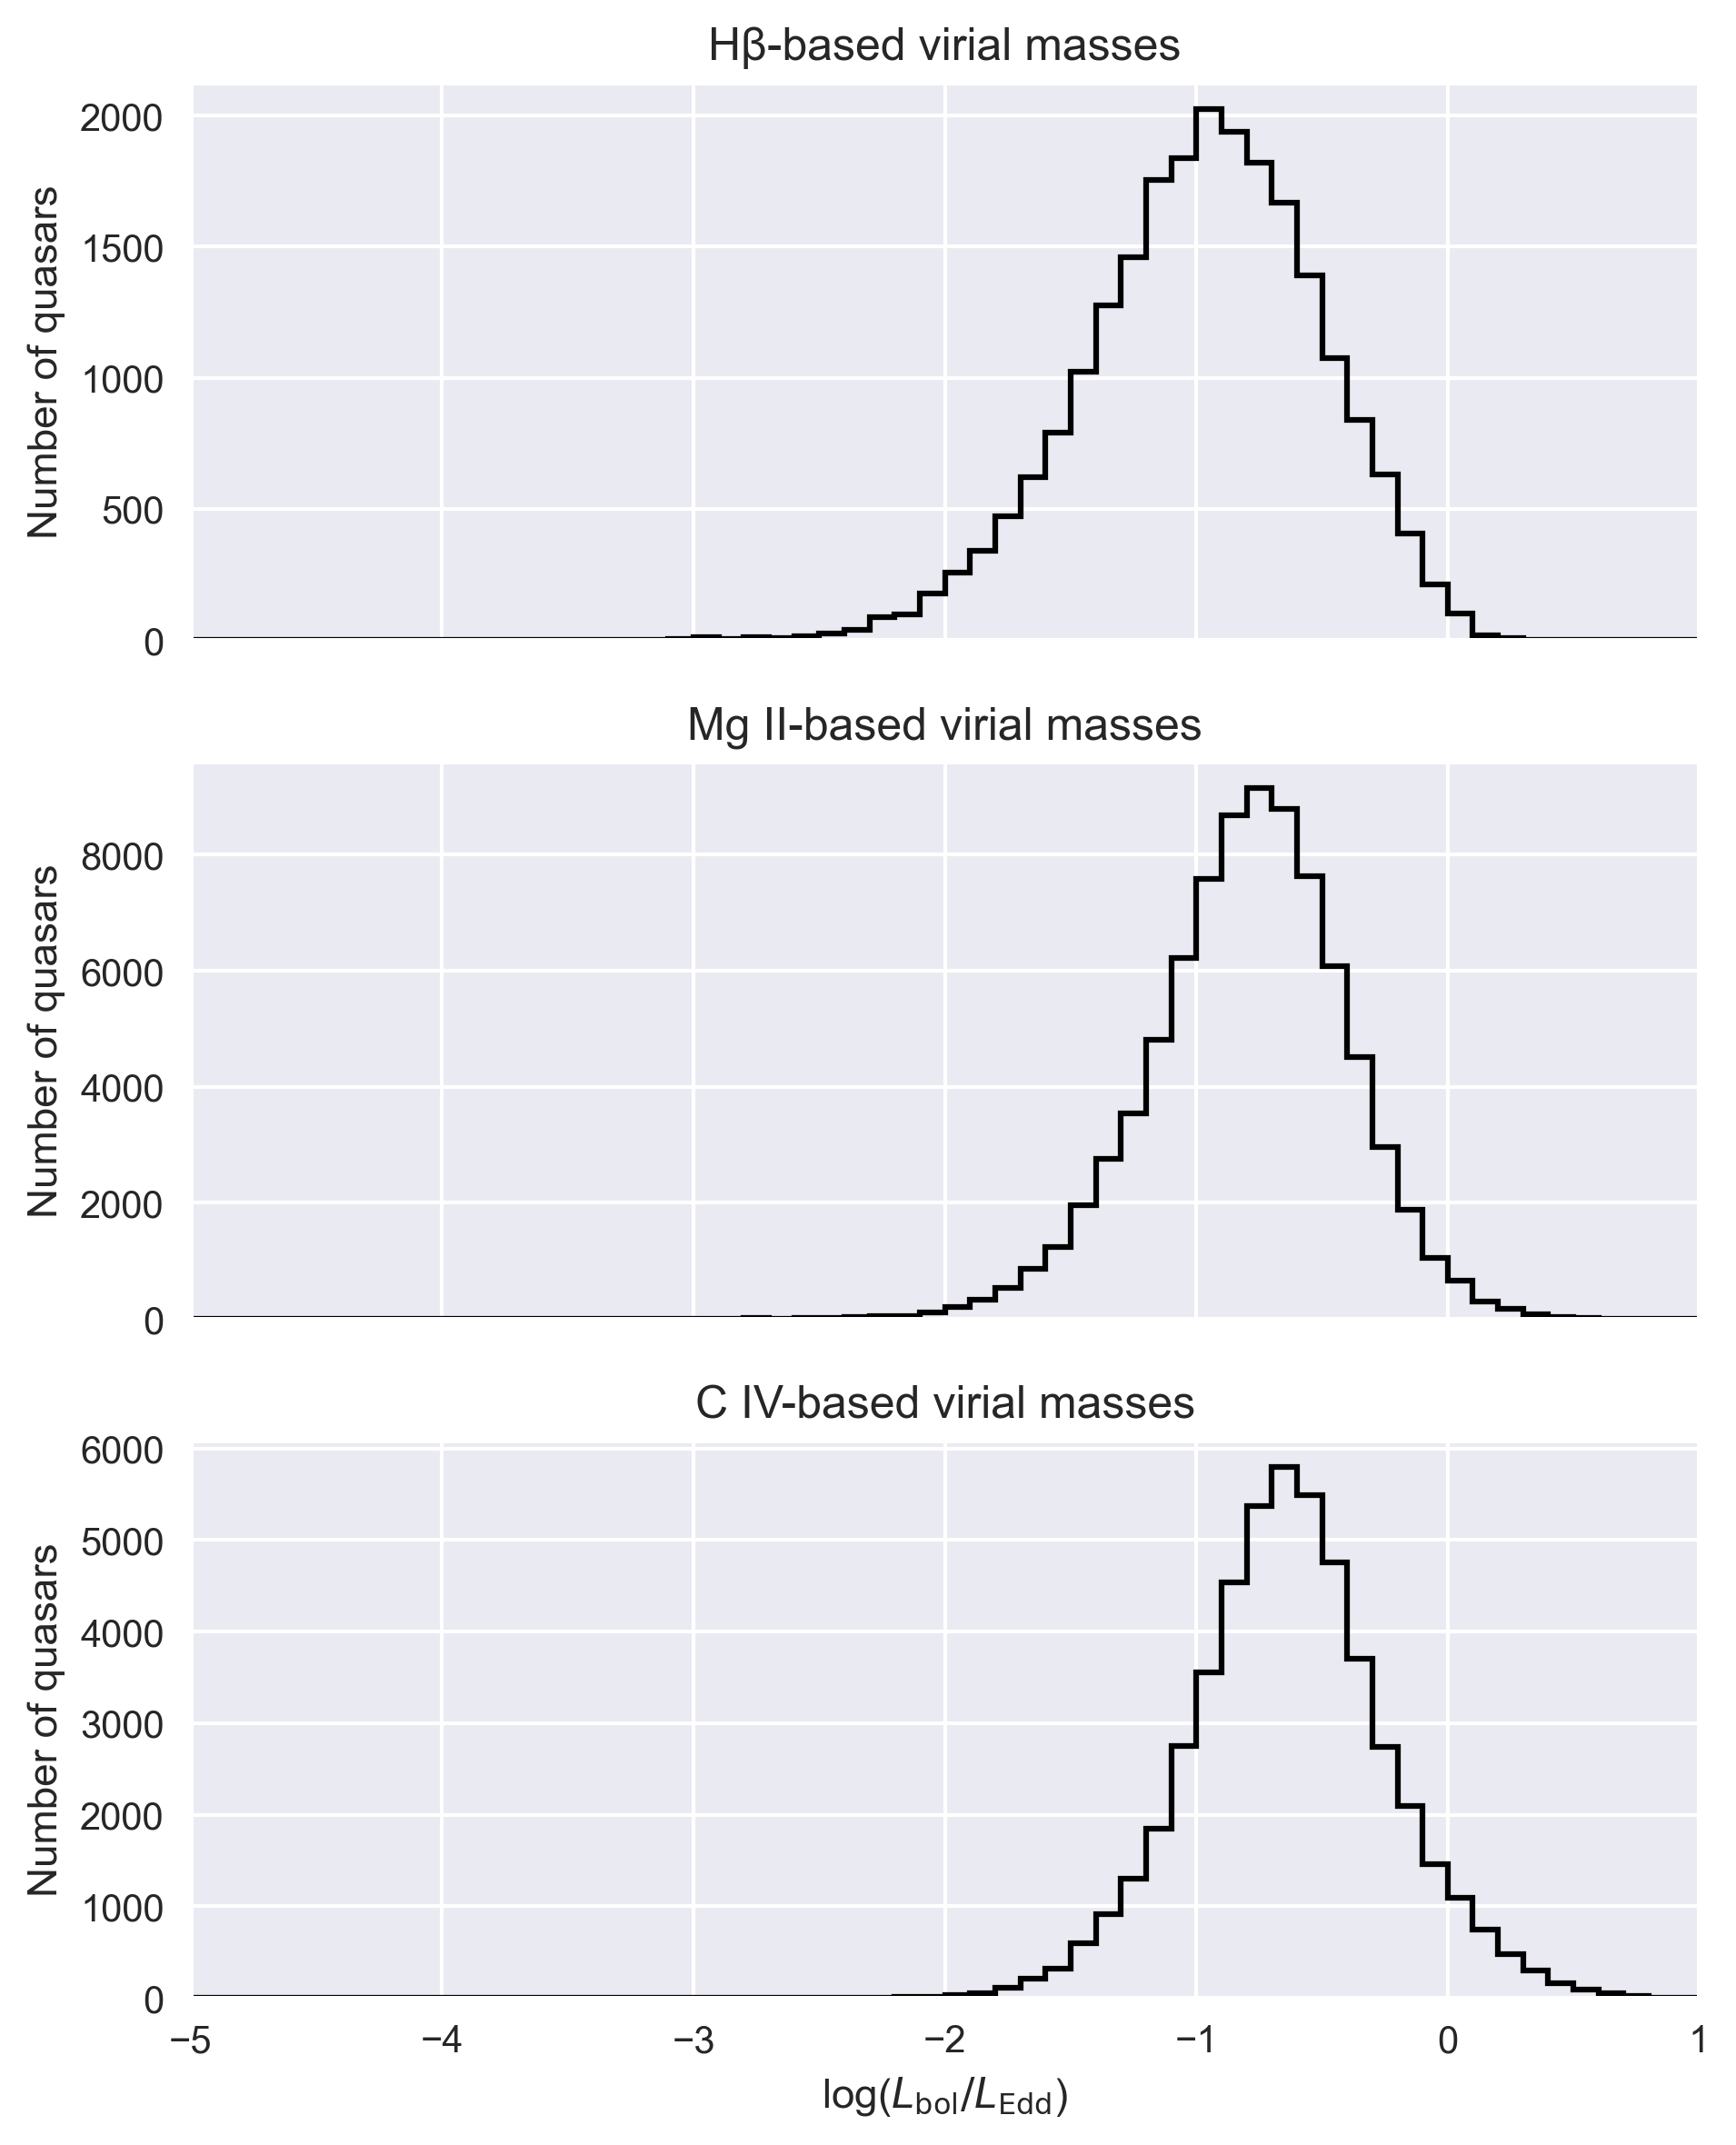

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# 1. Global settings
# -----------------------------
bins = np.arange(-5.0, 1.5, 0.1)
xlim = (-5, 1)
ylim = None  # let matplotlib scale y independently (paper does this)

# High-quality plotting defaults
plt.rcParams.update({
    "font.size": 11,
    "axes.linewidth": 1.2,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
})

# -----------------------------
# 2. Define subsamples
# -----------------------------

# Hβ-based Eddington ratios
hb = df[
    (df["z"] < 0.9) &
    (df["logBHHV"] > 5) &
    (df["logEdd"] > -5) &
    (df["logEdd"] < 2)
]

# Mg II-based Eddington ratios
mgii = df[
    (df["z"] >= 0.4) &
    (df["z"] <= 2.2) &
    (df["logBHMS"] > 5) &
    (df["logEdd"] > -5) &
    (df["logEdd"] < 2)
]

# C IV-based Eddington ratios
civ = df[
    (df["z"] > 1.5) &
    (df["logBHCV"] > 5) &
    (df["logEdd"] > -5) &
    (df["logEdd"] < 2)
]

# -----------------------------
# 3. Plot Figure 14 (multi-panel)
# -----------------------------
fig, axes = plt.subplots(
    3, 1,
    figsize=(6.5, 8.0),
    sharex=True,
    dpi=300
)

# ---- Panel 1: Hβ
axes[0].hist(
    hb["logEdd"],
    bins=bins,
    histtype="step",
    linewidth=1.5,
    color="black"
)
axes[0].set_ylabel("Number of quasars")
axes[0].set_title("Hβ-based virial masses")

# ---- Panel 2: Mg II
axes[1].hist(
    mgii["logEdd"],
    bins=bins,
    histtype="step",
    linewidth=1.5,
    color="black"
)
axes[1].set_ylabel("Number of quasars")
axes[1].set_title("Mg II-based virial masses")

# ---- Panel 3: C IV
axes[2].hist(
    civ["logEdd"],
    bins=bins,
    histtype="step",
    linewidth=1.5,
    color="black"
)
axes[2].set_ylabel("Number of quasars")
axes[2].set_title("C IV-based virial masses")
axes[2].set_xlabel(r"log($L_{\mathrm{bol}}/L_{\mathrm{Edd}}$)")

# ---- Axis limits
for ax in axes:
    ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)

plt.tight_layout()
plt.show()


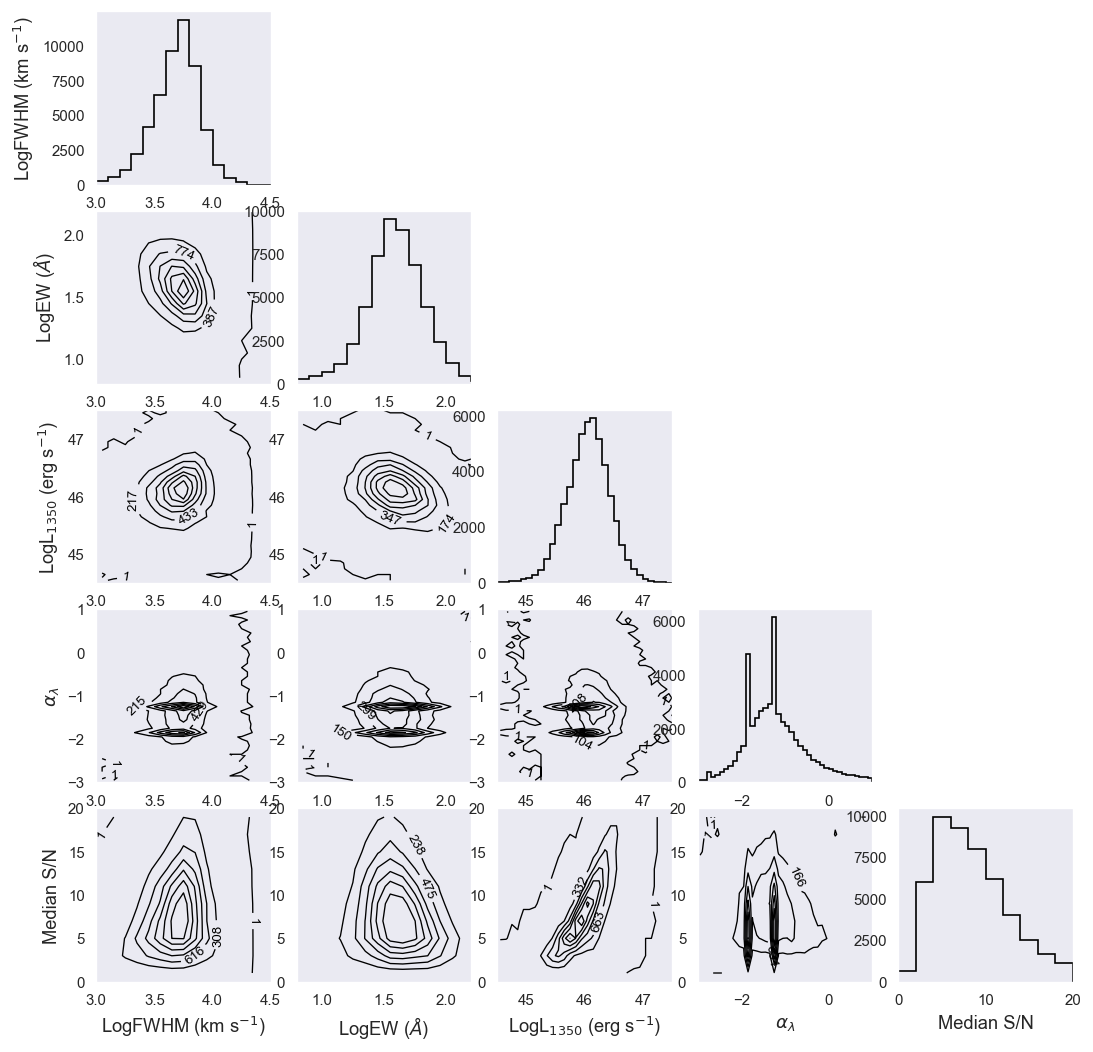

Saved: fig14_civ_triangle.png


In [37]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import ascii

# ----------------------------
# 1) Load CDS table properly
# ----------------------------
DATA_PATH = "../data/catalog.dat"      # your ApJS 194 Catalog.dat (rename if needed)
README_PATH = "../data/ReadMe"         # the CDS ReadMe you saved

t = ascii.read(DATA_PATH, readme=README_PATH)  # format guessed as CDS with readme

# ----------------------------
# 2) Robust column fetch helper
# ----------------------------
def get_col(table, candidates):
    """
    Return the first column in `table` whose name matches any candidate
    (exact match first, then substring match).
    """
    names = list(table.colnames)

    # exact match
    for c in candidates:
        if c in names:
            return table[c]

    # substring match (case-insensitive)
    lower_names = [n.lower() for n in names]
    for c in candidates:
        c_low = c.lower()
        for n, n_low in zip(names, lower_names):
            if c_low in n_low:
                return table[n]

    raise KeyError(f"None of these columns found: {candidates}\nAvailable columns start: {names[:25]} ...")

# ----------------------------
# 3) Pull Fig. 14 variables
# ----------------------------
# CIV FWHM (km/s): label in ReadMe is W(CIV)
W_CIV = np.array(get_col(t, ["W(CIV)", "W_CIV", "W_CIV_", "W_CIV__"]), dtype=float)

# CIV EW (Angstrom): label in ReadMe is EWCIV (units shown as 0.1 nm, i.e., Å)
EW_CIV = np.array(get_col(t, ["EWCIV", "EW_CIV", "EW_CIV_"]), dtype=float)

# log L1350
logL1350 = np.array(get_col(t, ["logL1350", "LOG_L1350", "logL_1350"]), dtype=float)

# continuum slope for CIV region: alpCIV (alpha_lambda)
alpha = np.array(get_col(t, ["alpCIV", "alpCIV_", "alphaCIV", "alp_CIV"]), dtype=float)

# Median S/N for CIV region: SN(CIV)
sn = np.array(get_col(t, ["SN(CIV)", "SN_CIV", "SN_CIV_", "SN_CIV__"]), dtype=float)

# ----------------------------
# 4) Clean + compute logs
# ----------------------------
# In this catalog, missing values are sometimes encoded as 0, -1, -999, etc.
mask = np.isfinite(W_CIV) & np.isfinite(EW_CIV) & np.isfinite(logL1350) & np.isfinite(alpha) & np.isfinite(sn)
mask &= (W_CIV > 0) & (EW_CIV > 0)                    # must be positive for log10
mask &= (logL1350 > 0)                                # should be >0
mask &= (alpha > -900)                                # remove -999 sentinels
mask &= (sn >= 0)

W_CIV = W_CIV[mask]
EW_CIV = EW_CIV[mask]
logL1350 = logL1350[mask]
alpha = alpha[mask]
sn = sn[mask]

x_logFWHM = np.log10(W_CIV)
x_logEW   = np.log10(EW_CIV)

# ----------------------------
# 5) Define plotting ranges (match paper figure)
# ----------------------------
# These are read off the printed axes in the PDF page you shared.
ranges = {
    "logFWHM": (3.0, 4.5),
    "logEW":   (0.8, 2.2),
    "logL1350":(44.5, 47.5),
    "alpha":   (-3.0, 1.0),
    "sn":      (0.0, 20.0),
}

labels = {
    "logFWHM": r"LogFWHM (km s$^{-1}$)",
    "logEW":   r"LogEW ($\AA$)",
    "logL1350":r"LogL$_{1350}$ (erg s$^{-1}$)",
    "alpha":   r"$\alpha_\lambda$",
    "sn":      r"Median S/N",
}

data = {
    "logFWHM": x_logFWHM,
    "logEW": x_logEW,
    "logL1350": logL1350,
    "alpha": alpha,
    "sn": sn,
}

order = ["logFWHM", "logEW", "logL1350", "alpha", "sn"]

# bin sizes per caption: Δ=0.1 for most axes; Δ=2 on S/N axis
binw = {"logFWHM":0.1, "logEW":0.1, "logL1350":0.1, "alpha":0.1, "sn":2.0}

# ----------------------------
# 6) Contour-from-grid function (paper rule)
# ----------------------------
def density_contour(ax, x, y, xname, yname, nlevels=8, label_outer=3):
    xmin, xmax = ranges[xname]
    ymin, ymax = ranges[yname]

    dx = binw[xname]
    dy = binw[yname]

    xb = np.arange(xmin, xmax + dx, dx)
    yb = np.arange(ymin, ymax + dy, dy)

    H, xedges, yedges = np.histogram2d(x, y, bins=[xb, yb])
    # histogram2d returns shape (len(xb)-1, len(yb)-1)
    # For contouring, use bin centers:
    xc = 0.5*(xedges[:-1] + xedges[1:])
    yc = 0.5*(yedges[:-1] + yedges[1:])
    X, Y = np.meshgrid(xc, yc, indexing="xy")

    Z = H.T  # transpose so Z matches X,Y orientation

    # Choose linear spaced contour levels between >0 and max
    zmax = Z.max()
    if zmax <= 0:
        return

    zmin = Z[Z > 0].min() if np.any(Z > 0) else 1.0
    levels = np.linspace(zmin, zmax, nlevels)

    cs = ax.contour(X, Y, Z, levels=levels, colors="black", linewidths=0.8)

    # Label outermost few contours (lowest density levels)
    # "outermost" corresponds to lower levels here.
    if label_outer > 0:
        use_levels = levels[:label_outer]
        ax.clabel(cs, levels=use_levels, inline=True, fmt=lambda v: f"{int(round(v))}", fontsize=8)

# ----------------------------
# 7) Build the triangle plot
# ----------------------------
N = len(order)
fig, axes = plt.subplots(N, N, figsize=(10.5, 10.5), dpi=120)

# Make it look like the paper: no grid, ticks on all sides, thin lines
for i in range(N):
    for j in range(N):
        ax = axes[i, j]
        ax.grid(False)
        ax.tick_params(direction="in", top=True, right=True, labelsize=9)
        for spine in ax.spines.values():
            spine.set_linewidth(0.8)

        # Upper triangle blank
        if j > i:
            ax.axis("off")

# Diagonal: 1D histograms
for k, name in enumerate(order):
    ax = axes[k, k]
    xmin, xmax = ranges[name]
    dx = binw[name]
    bins = np.arange(xmin, xmax + dx, dx)

    ax.hist(data[name], bins=bins, histtype="step", color="black", linewidth=1.0)
    ax.set_xlim(xmin, xmax)

    # Match paper: y-axis labeled as N only on diagonal panels (optional)
    if k == 0:
        ax.set_ylabel("N", fontsize=10)

# Lower triangle: contours
for i in range(1, N):
    for j in range(0, i):
        yname = order[i]
        xname = order[j]
        ax = axes[i, j]

        density_contour(ax, data[xname], data[yname], xname=xname, yname=yname, nlevels=8, label_outer=3)

        ax.set_xlim(*ranges[xname])
        ax.set_ylim(*ranges[yname])

# Axis labels: only leftmost column + bottom row
for i, yname in enumerate(order):
    axes[i, 0].set_ylabel(labels[yname], fontsize=11)

for j, xname in enumerate(order):
    axes[N-1, j].set_xlabel(labels[xname], fontsize=11)

# Tight layout similar to paper spacing
plt.subplots_adjust(wspace=0.15, hspace=0.15)

# Save high-resolution
out = "../figures/fig14_civ_triangle.png"
plt.savefig(out, dpi=400, bbox_inches="tight")
plt.show()

print(f"Saved: {out}")


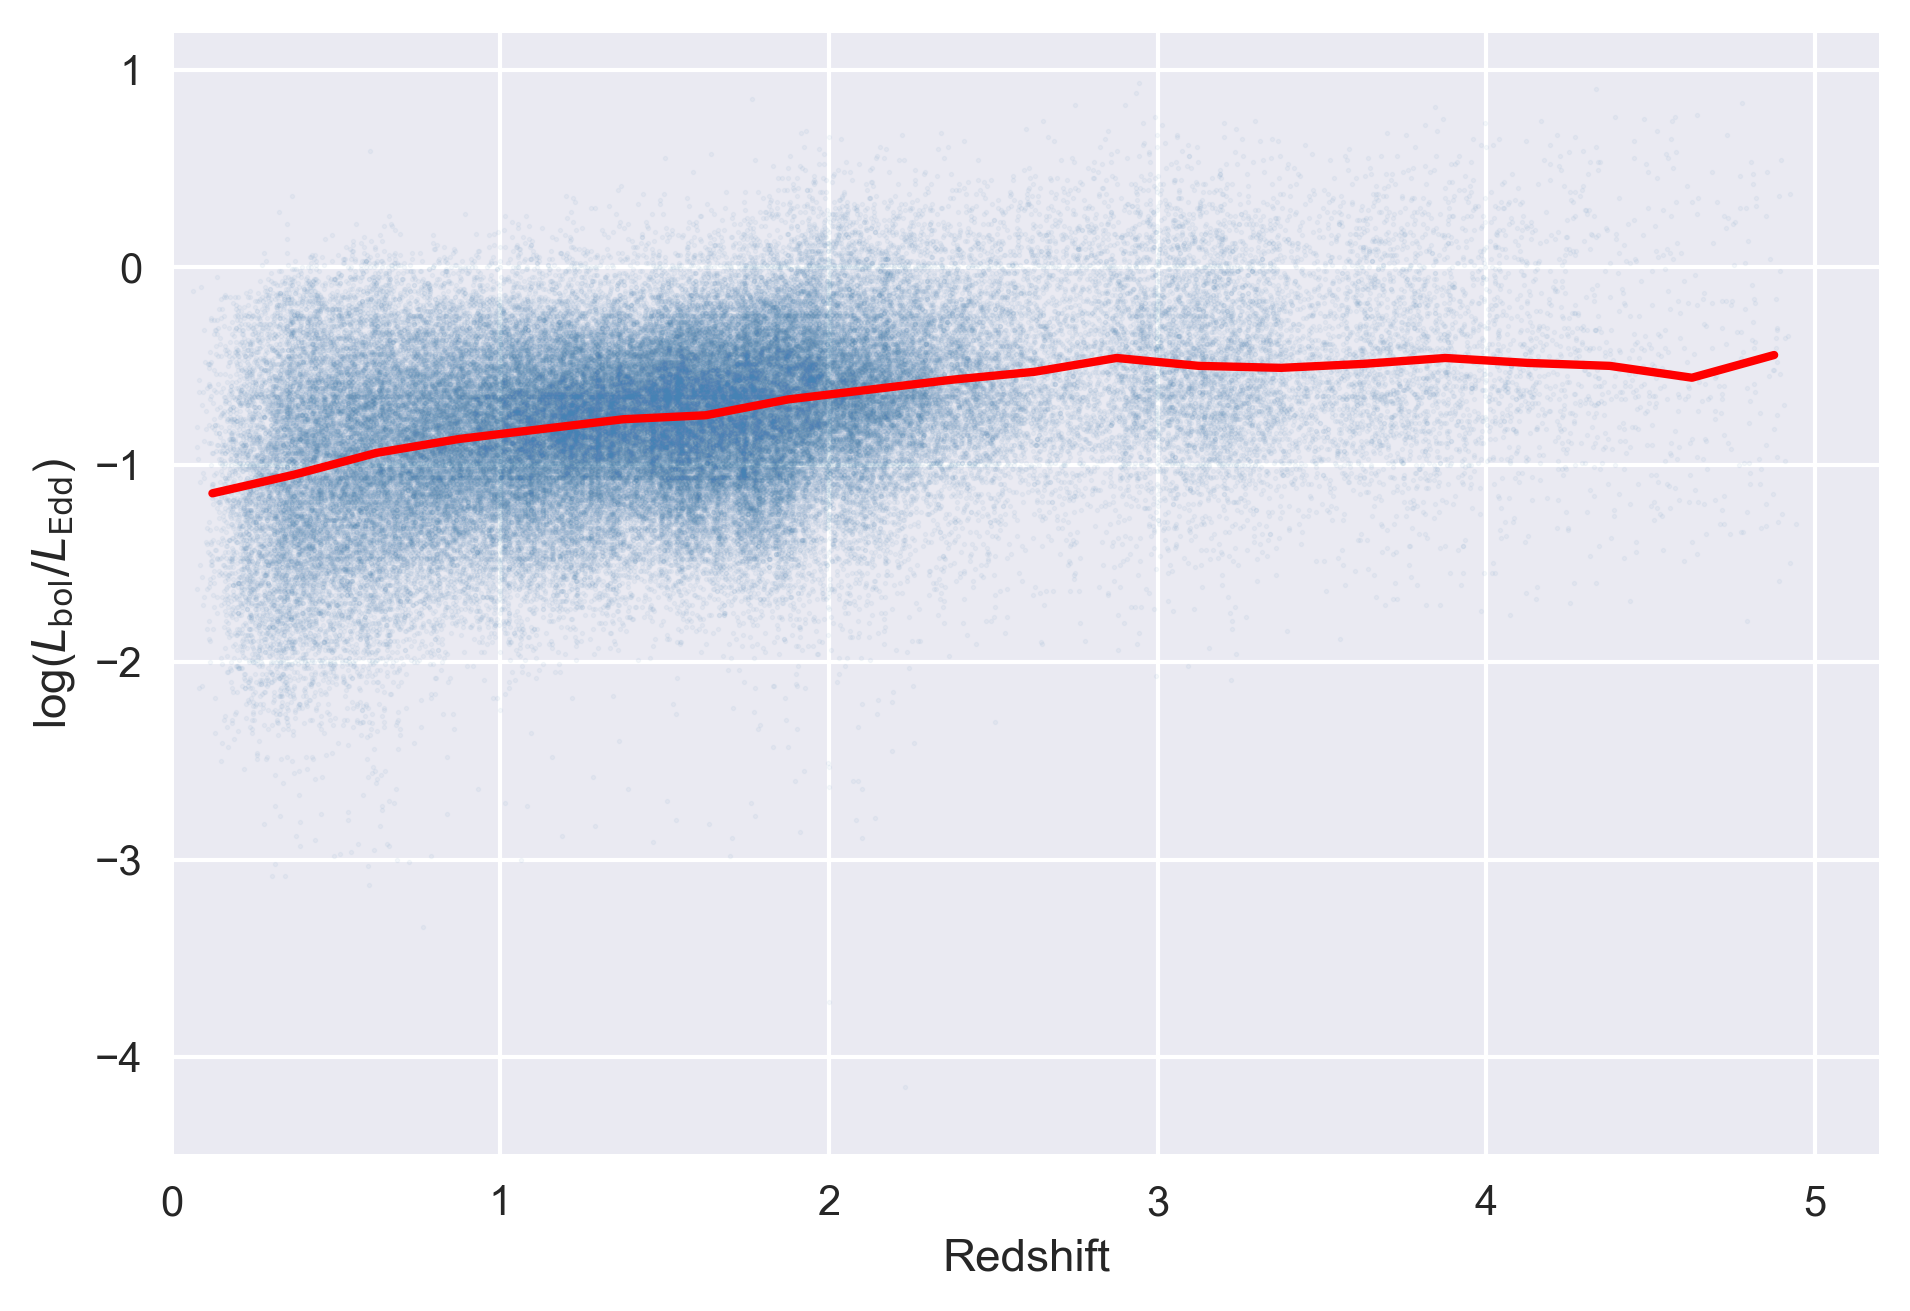

In [38]:
# ----------------------------
# 1. Clean parent sample
# ----------------------------
mask = (
    (df["z"] > 0) &
    (df["logEdd"] > -5) &
    (df["logEdd"] < 2)
)

z = df.loc[mask, "z"].values
logEdd = df.loc[mask, "logEdd"].values

# ----------------------------
# 2. Redshift binning
# ----------------------------
z_bins = np.arange(0.0, 5.5, 0.25)
z_centers = 0.5 * (z_bins[:-1] + z_bins[1:])

median_logEdd = []
for zmin, zmax in zip(z_bins[:-1], z_bins[1:]):
    in_bin = (z >= zmin) & (z < zmax)
    if np.sum(in_bin) > 20:
        median_logEdd.append(np.median(logEdd[in_bin]))
    else:
        median_logEdd.append(np.nan)

median_logEdd = np.array(median_logEdd)

# ----------------------------
# 3. Plot
# ----------------------------
plt.figure(figsize=(6.5, 4.5), dpi=300)

plt.scatter(z, logEdd, s=1, alpha=0.05, color="steelblue")
plt.plot(z_centers, median_logEdd, color="red", lw=2)

plt.xlabel("Redshift")
plt.ylabel(r"log($L_{\mathrm{bol}}/L_{\mathrm{Edd}}$)")
plt.xlim(0, 5.2)
plt.ylim(-4.5, 1.2)

plt.tight_layout()
plt.savefig("../figures/fig8_logEdd_vs_z.png", dpi=300)
plt.show()
